# CS02: 6-month future spend regression (Online Retail II)

Target: revenue from each customer in (snapshot, snapshot + 180 days].
Features use only transactions before the snapshot.
Training snapshots end their target windows before the test snapshot starts.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cvreg.core import (
    FEATURE_COLS,
    HORIZON_DAYS,
    RANDOM_STATE,
    TEST_SNAPSHOT,
    TRAIN_SNAPSHOTS,
    assert_time_ordered,
    build_panel,
    data_path,
    fit_xgb,
    load_retail,
    model_matrix,
    regression_metrics,
    segment_mean_baseline,
)

FIG = Path.cwd().parent / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
assert_time_ordered(TRAIN_SNAPSHOTS, TEST_SNAPSHOT, HORIZON_DAYS)

In [2]:
tx = load_retail()
print("data:", data_path())
print("train snapshots:", [d.date().isoformat() for d in TRAIN_SNAPSHOTS], "| test snapshot:", TEST_SNAPSHOT.date())

train = build_panel(tx, TRAIN_SNAPSHOTS)
test = build_panel(tx, [TEST_SNAPSHOT])
print("train rows:", len(train), "| test rows:", len(test))
print("share with zero future spend (train / test):",
      round((train.target == 0).mean(), 3), round((test.target == 0).mean(), 3))
test[["target"]].describe().round(2)

data: /home/patotricks15/.local/share/clv-data/online-retail-ii/online_retail_II.csv
train snapshots: ['2010-01-01', '2010-02-01', '2010-03-01'] | test snapshot: 2010-09-01


train rows: 4005 | test rows: 3321
share with zero future spend (train / test): 0.249 0.356


,target
count,3321.00
mean,1201.74
std,4986.45
min,0.00
25%,0.00
50%,322.40
75%,1017.82
max,150085.63


In [3]:
baseline_pred = segment_mean_baseline(train, test)
base = regression_metrics(test["target"].to_numpy(), baseline_pred)
print("segment-mean baseline (frequency quintile):", {k: round(v, 2) for k, v in base.items()})

segment-mean baseline (frequency quintile): {'mae': 2099.24, 'rmse': 5075.96}


In [4]:
model = fit_xgb(model_matrix(train), train["target"].to_numpy())
model_pred = np.clip(model.predict(model_matrix(test)), 0, None)
mdl = regression_metrics(test["target"].to_numpy(), model_pred)
print("XGBoost:", {k: round(v, 2) for k, v in mdl.items()})

results = pd.DataFrame({"baseline": base, "xgboost": mdl}).T.round(2)
print("improvement in MAE:", round(1 - mdl["mae"] / base["mae"], 4))
results

XGBoost: {'mae': 1479.34, 'rmse': 4389.92}
improvement in MAE: 0.2953


,mae,rmse
baseline,2099.24,5075.96
xgboost,1479.34,4389.92


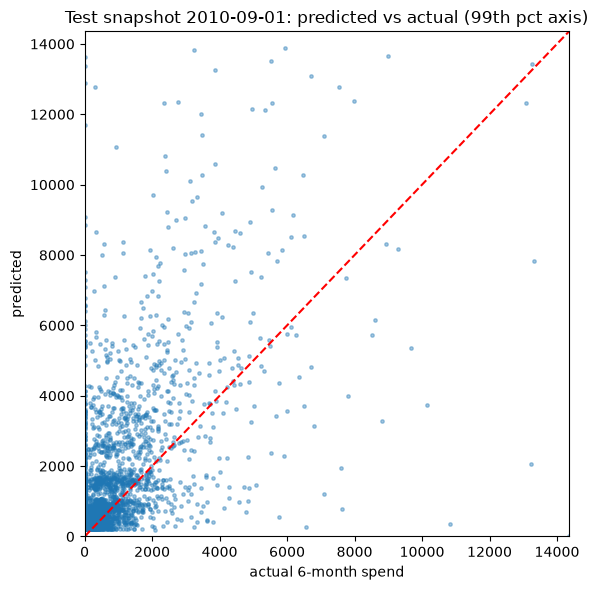

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
lim = float(np.percentile(test["target"], 99))
ax.scatter(test["target"], model_pred, s=6, alpha=0.4)
ax.plot([0, lim], [0, lim], color="red", linestyle="--")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel("actual 6-month spend")
ax.set_ylabel("predicted")
ax.set_title(f"Test snapshot {TEST_SNAPSHOT.date()}: predicted vs actual (99th pct axis)")
fig.tight_layout()
fig.savefig(FIG / "cs02_pred_vs_actual.png", dpi=120)
plt.show()

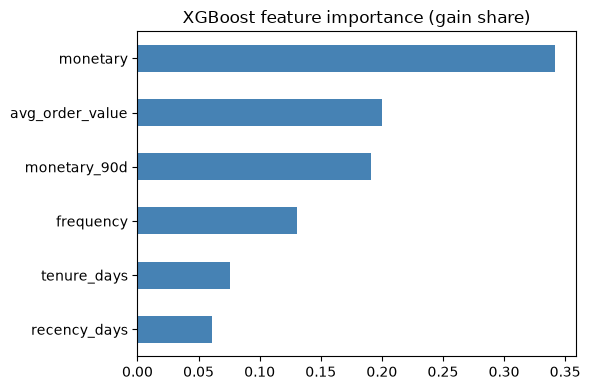

monetary           0.342
avg_order_value    0.200
monetary_90d       0.191
frequency          0.131
tenure_days        0.076
recency_days       0.061
dtype: float32

In [6]:
importance = pd.Series(model.feature_importances_, index=FEATURE_COLS).sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
importance.plot.barh(ax=ax, color="steelblue")
ax.set_title("XGBoost feature importance (gain share)")
fig.tight_layout()
fig.savefig(FIG / "cs02_feature_importance.png", dpi=120)
plt.show()
importance.sort_values(ascending=False).round(3)